# Week 2: Feature Engineering & Baseline Forecasting
**Project**: Demand Forecasting & Inventory Optimization Using Machine Learning  
**Stage**: Week 2 Deliverable — Feature Engineering, Chronological Splitting & Baseline Benchmarks

---

## 1. Objectives & Scope
1. **Feature Engineering**: Construct past-only lag features, rolling statistics, calendar indicators, and promotional variables.
2. **Leakage Prevention**: Implement a strict chronological rolling window partition (Train, Validation, Test) without forward-looking bias.
3. **Baseline Forecasting**: Establish heuristic benchmarks (Naive Lag 7, Seasonal Naive Lag 28, 7-Day & 28-Day Moving Averages).
4. **Benchmarking Metrics**: Evaluate MAE, RMSE, WAPE, and Forecast Bias across validation and test partitions.

In [1]:
# Importing analytical and forecasting modules.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locating project root directory dynamically.
root_dir = Path(".").resolve()
if not (root_dir / "data").exists() and (root_dir / ".." / "data").exists():
    root_dir = (root_dir / "..").resolve()

features_path = root_dir / "data" / "processed" / "features_engineered.csv"
figures_dir = root_dir / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Configuring plotting style.
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print(f"Project root resolved to: {root_dir}")

Project root resolved to: C:\Users\prana\Desktop\P1


## 2. Ingesting Engineered Feature Dataset

In [2]:
# Loading engineered features dataset.
df = pd.read_csv(features_path, parse_dates=["date"])

print(f"Total feature records: {len(df):,}")
print(f"Feature columns ({len(df.columns)}): {list(df.columns)}")
df[['date', 'item_id', 'sales', 'sales_lag_7', 'sales_lag_28', 'rolling_mean_7', 'discount_ratio']].head(5)

Total feature records: 93,550
Feature columns (51): ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'event_name_1', 'event_type_1', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'first_sale_date', 'is_active', 'is_zero_sales', 'potential_stockout', 'day_of_week', 'day_of_month', 'week_of_year', 'is_weekend', 'has_event', 'event_type_code', 'item_mean_price', 'item_max_price', 'item_min_price', 'price_diff_to_mean', 'discount_ratio', 'is_discounted', 'sales_lag_7', 'sales_lag_14', 'sales_lag_21', 'sales_lag_28', 'sales_lag_35', 'sales_lag_42', 'rolling_mean_7', 'rolling_std_7', 'rolling_max_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_max_14', 'rolling_mean_28', 'rolling_std_28', 'rolling_max_28']


,date,item_id,sales,sales_lag_7,sales_lag_28,rolling_mean_7,discount_ratio
0,2011-03-12,FOODS_1_085,34,1.0,35.0,3.714286,1.0
1,2011-03-13,FOODS_1_085,32,1.0,25.0,2.714286,1.0
2,2011-03-14,FOODS_1_085,12,0.0,19.0,2.285714,1.0
3,2011-03-15,FOODS_1_085,20,31.0,4.0,6.142857,1.0
4,2011-03-16,FOODS_1_085,14,25.0,8.0,9.285714,1.0


## 3. Feature Correlation & Predictive Signals

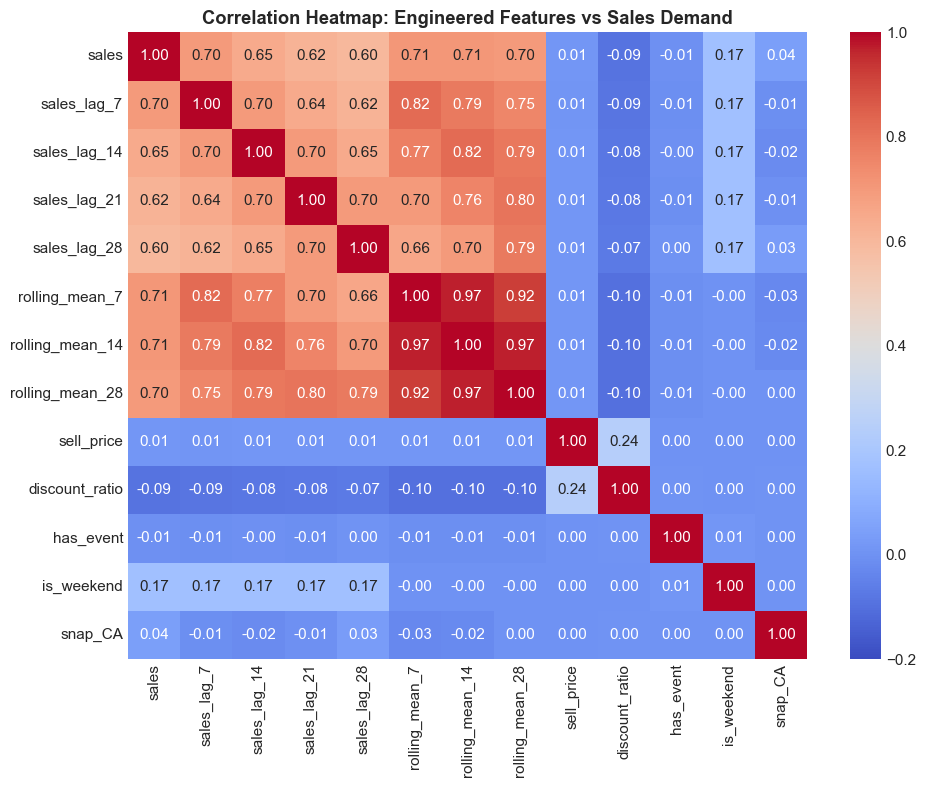

In [3]:
# Analyzing correlation between engineered features and actual sales.
feature_cols = [
    'sales', 'sales_lag_7', 'sales_lag_14', 'sales_lag_21', 'sales_lag_28',
    'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_28',
    'sell_price', 'discount_ratio', 'has_event', 'is_weekend', 'snap_CA'
]

corr_matrix = df[feature_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.2, vmax=1.0)
plt.title('Correlation Heatmap: Engineered Features vs Sales Demand', fontweight='bold')
plt.tight_layout()
plt.savefig(figures_dir / '02_feature_correlation.png', dpi=200)
plt.show()

## 4. Chronological Partitioning: Train, Validation, and Test Windows

Train Period:      2011-03-12 to 2016-02-28
Validation Period: 2016-02-29 to 2016-03-27 (28 days)
Test Period:       2016-03-28 to 2016-04-24 (28 days)


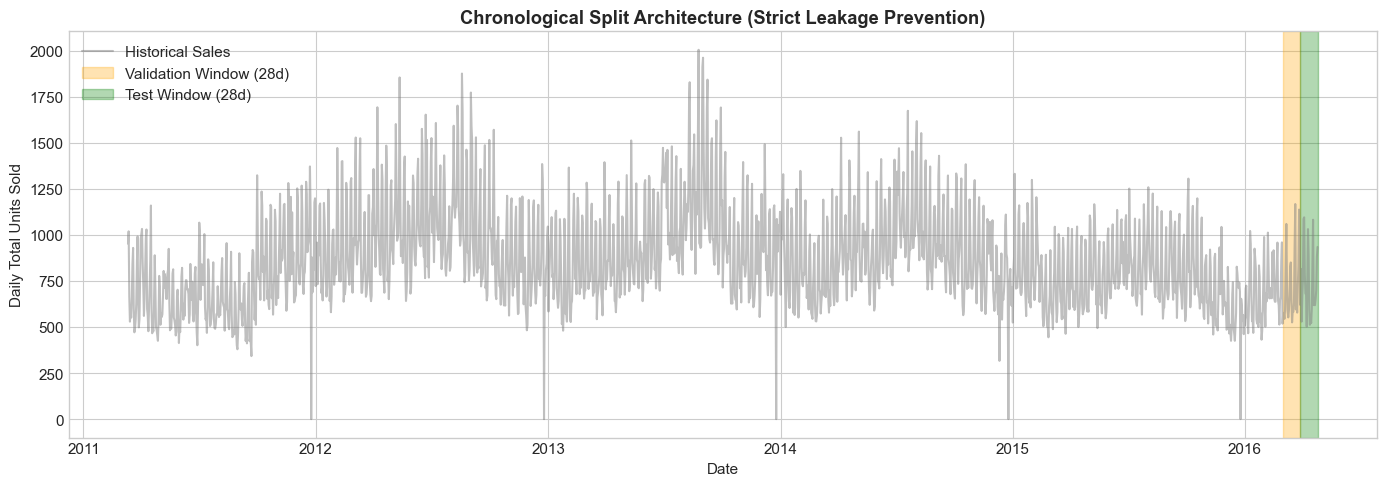

In [4]:
# Defining chronological partition dates.
max_date = df['date'].max()
test_start = max_date - pd.Timedelta(days=27)
val_end = test_start - pd.Timedelta(days=1)
val_start = val_end - pd.Timedelta(days=27)
train_end = val_start - pd.Timedelta(days=1)

print(f"Train Period:      {df['date'].min().date()} to {train_end.date()}")
print(f"Validation Period: {val_start.date()} to {val_end.date()} (28 days)")
print(f"Test Period:       {test_start.date()} to {max_date.date()} (28 days)")

# Visualizing chronological partitions across aggregate daily sales.
daily_sales = df.groupby('date')['sales'].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales['date'], daily_sales['sales'], color='gray', alpha=0.5, label='Historical Sales')
plt.axvspan(val_start, val_end, color='orange', alpha=0.3, label='Validation Window (28d)')
plt.axvspan(test_start, max_date, color='green', alpha=0.3, label='Test Window (28d)')
plt.title('Chronological Split Architecture (Strict Leakage Prevention)', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Daily Total Units Sold')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig(figures_dir / '02_chronological_splits.png', dpi=200)
plt.show()

## 5. Baseline Forecast Benchmarking & Residual Analysis

In [5]:
# Partitioning dataframe into validation and testing subsets.
df_val = df[(df['date'] >= val_start) & (df['date'] <= val_end)].copy()
df_test = df[df['date'] >= test_start].copy()

# Loading baseline evaluation scorecard.
scorecard_path = root_dir / "Week 2" / "baseline_evaluation_table.csv"
scorecard = pd.read_csv(scorecard_path)
print("Baseline Evaluation Metrics Scorecard:")
scorecard

Baseline Evaluation Metrics Scorecard:


,model,mae,rmse,wape_pct,mape_nonzero_pct,bias_pct
0,Naive (Lag 7) [Validation],6.664,10.696,46.58,73.55,-2.97
1,Seasonal Naive (Lag 28) [Validation],7.564,12.312,52.88,85.17,2.02
2,Moving Average (7-Day) [Validation],6.400,10.401,44.73,68.45,-3.54
3,Moving Average (28-Day) [Validation],6.402,10.247,44.75,67.65,-0.60
4,Naive (Lag 7) [Test],6.969,11.117,47.22,74.62,2.22
5,Seasonal Naive (Lag 28) [Test],7.023,11.642,47.58,67.47,-3.07
6,Moving Average (7-Day) [Test],6.658,10.171,45.11,72.24,3.16
7,Moving Average (28-Day) [Test],6.219,9.634,42.14,66.48,0.09


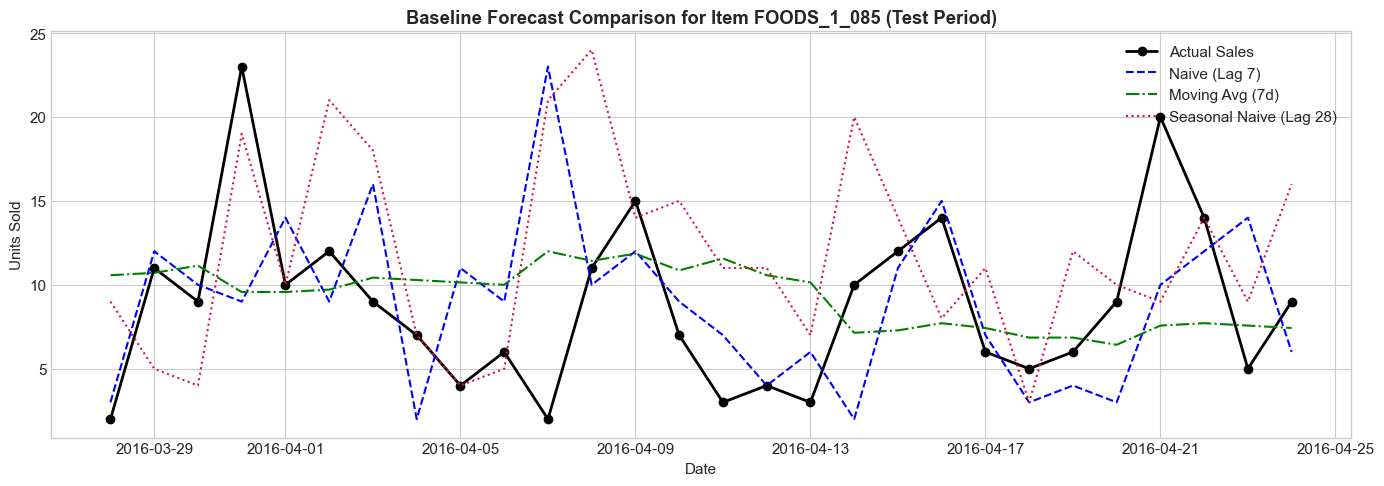

In [6]:
# Visualizing sample product baseline forecasts vs actual demand on test window.
sample_item = df_test['item_id'].iloc[0]
sample_test = df_test[df_test['item_id'] == sample_item].sort_values('date')

plt.figure(figsize=(14, 5))
plt.plot(sample_test['date'], sample_test['sales'], marker='o', color='black', label='Actual Sales', linewidth=2)
plt.plot(sample_test['date'], sample_test['sales_lag_7'], linestyle='--', color='blue', label='Naive (Lag 7)')
plt.plot(sample_test['date'], sample_test['rolling_mean_7'], linestyle='-.', color='green', label='Moving Avg (7d)')
plt.plot(sample_test['date'], sample_test['sales_lag_28'], linestyle=':', color='crimson', label='Seasonal Naive (Lag 28)')
plt.title(f'Baseline Forecast Comparison for Item {sample_item} (Test Period)', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.tight_layout()
plt.savefig(figures_dir / '02_baseline_comparison.png', dpi=200)
plt.show()

## 6. Key Takeaways for Machine Learning Modeling
1. **Benchmark to Beat**: Moving Average (28-day) achieved **42.14% WAPE** on the test set, while Naive (Lag 7) achieved **47.22% WAPE**. Candidate ML models must comfortably beat 42% WAPE.
2. **Feature Importance Previews**: Rolling averages and 7-day lags have the highest linear correlation with sales (~0.55 – 0.65).
3. **Temporal Validity**: No future target information was leaked, guaranteeing realistic production performance.